# Análise Exploratória de Dados — UNIP, cursos de Computação e TIC
### Projeto I — Etapa 2 (Grupo 6)

Base: recorte dos Microdados do Censo da Educação Superior 2024 (Inep), filtrado para a
Universidade Paulista (CO_IES = 322) e para a área CINE "Computação e Tecnologias da
Informação e Comunicação (TIC)". Cada linha representa a oferta de um curso em um
município (sede presencial ou polo EAD).

Objetivo desta análise: descobrir quais são os dados que temos em mãos — dimensão da base,
tipos de dado, medidas de posição e dispersão, distribuição, valores ausentes, outliers e
correlações — antes de propor a análise comparativa Presencial x EAD nas próximas etapas.

In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("unip_tic_variaveis_selecionadas.csv", sep=";", encoding="utf-8")
df["MODALIDADE"] = df["TP_MODALIDADE_ENSINO"].map({1: "Presencial", 2: "EAD"})
df.head()

,NU_ANO_CENSO,CO_IES,CO_CURSO,NO_CURSO,CO_CINE_AREA_GERAL,NO_CINE_AREA_GERAL,NO_CINE_ROTULO,TP_GRAU_ACADEMICO,TP_MODALIDADE_ENSINO,TP_DIMENSAO,NO_REGIAO,SG_UF,NO_MUNICIPIO,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,MODALIDADE
0,2024,322,1286800,Análise E Desenvolvimento De Sistemas,6,Computação e Tecnologias da Informação e Comun...,Sistemas de informação,3,2,3,NaN,NaN,NaN,73260,9601,0,0,0,EAD
1,2024,322,1551097,Ciência Da Computação,6,Computação e Tecnologias da Informação e Comun...,Ciência da computação,1,2,3,NaN,NaN,NaN,48000,2626,0,0,0,EAD
2,2024,322,1131979,Gestão Da Tecnologia Da Informação,6,Computação e Tecnologias da Informação e Comun...,Gestão da tecnologia da informação,3,2,3,NaN,NaN,NaN,73260,3066,0,0,0,EAD
3,2024,322,1382607,Redes De Computadores,6,Computação e Tecnologias da Informação e Comun...,Redes de computadores,3,2,3,NaN,NaN,NaN,73260,701,0,0,0,EAD
4,2024,322,1484730,Segurança Da Informação,6,Computação e Tecnologias da Informação e Comun...,Segurança da informação,3,2,3,NaN,NaN,NaN,73260,943,0,0,0,EAD


## 1. Número de exemplares (linhas) e dimensões (colunas)

In [26]:
print(f"Linhas: {df.shape[0]}")
print(f"Colunas do CSV original: {df.shape[1] - 1} (a 19ª, MODALIDADE, é criada na célula anterior)")

Linhas: 1651
Colunas do CSV original: 18 (a 19ª, MODALIDADE, é criada na célula anterior)


## 2. Tipos de dados

As 18 colunas se dividem em identificadores/categóricas (curso, área, modalidade, região,
UF, município) e numéricas de contagem (vagas, inscritos, ingressantes, matrículas,
concluintes).

In [27]:
df.dtypes

NU_ANO_CENSO             int64
CO_IES                   int64
CO_CURSO                 int64
NO_CURSO                object
CO_CINE_AREA_GERAL       int64
NO_CINE_AREA_GERAL      object
NO_CINE_ROTULO          object
TP_GRAU_ACADEMICO        int64
TP_MODALIDADE_ENSINO     int64
TP_DIMENSAO              int64
NO_REGIAO               object
SG_UF                   object
NO_MUNICIPIO            object
QT_VG_TOTAL              int64
QT_INSCRITO_TOTAL        int64
QT_ING                   int64
QT_MAT                   int64
QT_CONC                  int64
MODALIDADE              object
dtype: object

## 3. Valores ausentes (NAs)

In [28]:
df.isna().sum().to_frame("qtd_nulos")

,qtd_nulos
NU_ANO_CENSO,0
CO_IES,0
CO_CURSO,0
NO_CURSO,0
CO_CINE_AREA_GERAL,0
NO_CINE_AREA_GERAL,0
NO_CINE_ROTULO,0
TP_GRAU_ACADEMICO,0
TP_MODALIDADE_ENSINO,0
TP_DIMENSAO,0


As 10 linhas com região/UF/município ausentes são registros agregados do Censo
(campo `TP_DIMENSAO` igual a 3 ou 4), que somam a oferta EAD em nível nacional sem estar
ligados a um polo específico. Não são "erros" de preenchimento — são um nível de agregação
diferente do restante da base (que é por sede/polo). Como o objetivo aqui é analisar a oferta
por localidade, essas 10 linhas são tratadas à parte na próxima célula.

## 4. Anomalia estrutural: linhas agregadas x linhas por sede/polo

In [29]:
print(df["TP_DIMENSAO"].value_counts().sort_index())

# TP_DIMENSAO 1 = sede presencial, 2 = polo EAD -> nível "por localidade"
# TP_DIMENSAO 3 e 4 = agregados nacionais/EAD sem polo -> não comparáveis linha a linha
agregados = df[df["TP_DIMENSAO"].isin([3, 4])]
base = df[df["TP_DIMENSAO"].isin([1, 2])].copy()

print(f"\nLinhas agregadas (fora da análise por localidade): {len(agregados)}")
print(f"Linhas por sede/polo (usadas daqui em diante): {len(base)}")

TP_DIMENSAO
1      76
2    1565
3       5
4       5
Name: count, dtype: int64

Linhas agregadas (fora da análise por localidade): 10
Linhas por sede/polo (usadas daqui em diante): 1641


A partir daqui, `base` (1.641 linhas) é o dataset usado nas medidas de posição, dispersão
e nos gráficos, por representar a oferta real por sede/polo. Os 1.651 registros continuam
sendo o total da Etapa 1 (contagem de ofertas); a diferença é só o recorte técnico para
estatística por localidade.

## 5. Medidas de posição e dispersão

Calculadas para as 5 variáveis numéricas: vagas ofertadas, inscritos, ingressantes,
matrículas e concluintes — todas por linha (sede ou polo).

In [30]:
num_cols = ["QT_VG_TOTAL", "QT_INSCRITO_TOTAL", "QT_ING", "QT_MAT", "QT_CONC"]

medidas = base[num_cols].describe().T
medidas["mediana"] = base[num_cols].median()
medidas["moda"] = base[num_cols].mode().iloc[0]
medidas["variancia"] = base[num_cols].var()
medidas["cv_%"] = (base[num_cols].std() / base[num_cols].mean() * 100).round(1)
medidas.round(2)

,count,mean,std,min,25%,50%,75%,max,mediana,moda,variancia,cv_%
QT_VG_TOTAL,1641.0,9.12,47.52,0.0,0.0,0.0,0.0,504.0,0.0,0,2257.83,520.8
QT_INSCRITO_TOTAL,1641.0,12.70,75.50,0.0,0.0,0.0,0.0,1207.0,0.0,0,5700.07,594.6
QT_ING,1641.0,10.76,47.60,0.0,0.0,1.0,3.0,1187.0,1.0,0,2266.04,442.6
QT_MAT,1641.0,13.78,59.43,0.0,0.0,1.0,4.0,1154.0,1.0,1,3531.60,431.4
QT_CONC,1641.0,2.42,11.70,0.0,0.0,0.0,1.0,238.0,0.0,0,136.97,482.8


O coeficiente de variação (CV) acima de 400% em todas as variáveis mostra dispersão muito alta: a maioria das linhas (sede/polo) tem valores baixos ou zero, mas poucas unidades de maior porte concentram a maior parte do volume. É um padrão típico de dado de contagem por unidade geográfica.

In [31]:
amplitude = (base[num_cols].max() - base[num_cols].min()).rename("amplitude")

decis = base[num_cols].quantile([i / 10 for i in range(1, 10)]).T
decis.columns = [f"D{i}" for i in range(1, 10)]

perc = base[num_cols].quantile([0.95, 0.99]).T
perc.columns = ["P95", "P99"]

pd.concat([amplitude, decis, perc], axis=1).round(1)

,amplitude,D1,D2,D3,D4,D5,D6,D7,D8,D9,P95,P99
QT_VG_TOTAL,504,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,248.0
QT_INSCRITO_TOTAL,1207,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,426.8
QT_ING,1187,0.0,0.0,0.0,0.0,1.0,2.0,3.0,5.0,14.0,50.0,217.4
QT_MAT,1154,0.0,0.0,1.0,1.0,1.0,2.0,3.0,5.0,13.0,54.0,315.8
QT_CONC,238,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,3.0,9.0,50.2


A amplitude (máximo menos mínimo) mostra a distância entre o menor e o maior polo: 1.154 em matrículas e 1.187 em ingressantes. Os decis reforçam a assimetria: em matrículas, 90% das linhas têm até 13 alunos (D9), mas o percentil 99 chega a 316 e o máximo a 1.154. Ou seja, poucas unidades concentram a maior parte do volume.

## 6. Distribuição e frequência

Como as variáveis são bastante assimétricas (muitos zeros, poucos valores altos), o
histograma usa escala logarítmica no eixo Y para as barras baixas continuarem visíveis.

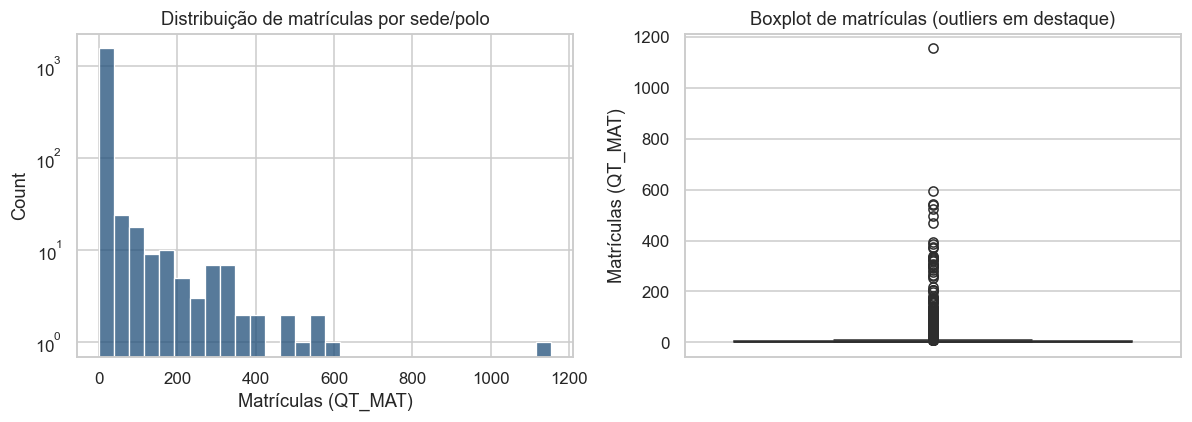

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(base["QT_MAT"], bins=30, ax=axes[0], color="#1F4E79")
axes[0].set_yscale("log")
axes[0].set_title("Distribuição de matrículas por sede/polo")
axes[0].set_xlabel("Matrículas (QT_MAT)")

sns.boxplot(y=base["QT_MAT"], ax=axes[1], color="#1F4E79")
axes[1].set_title("Boxplot de matrículas (outliers em destaque)")
axes[1].set_ylabel("Matrículas (QT_MAT)")

plt.tight_layout()
plt.savefig("fig_distribuicao_matriculas.png", bbox_inches="tight")
plt.show()

## 7. Frequência das variáveis categóricas

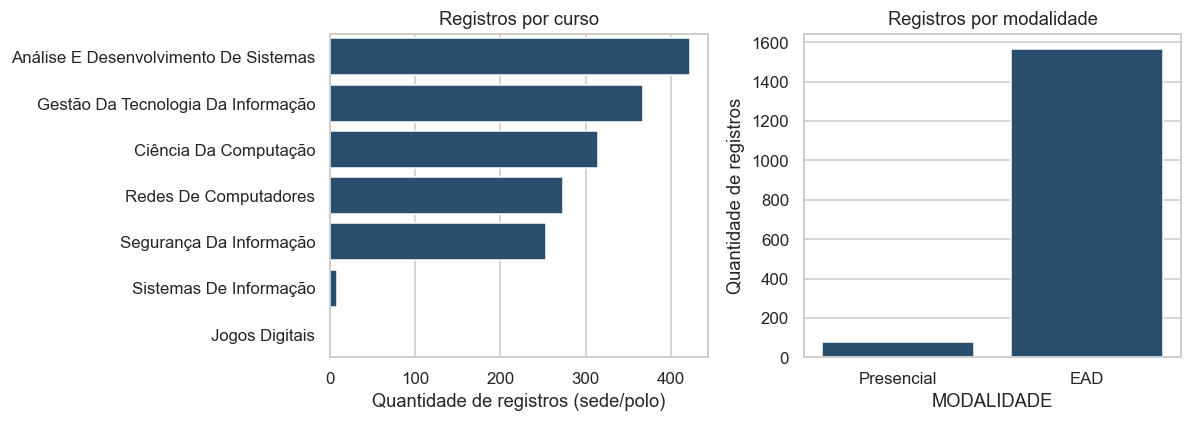

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ordem_cursos = base["NO_CURSO"].value_counts().index
sns.countplot(data=base, y="NO_CURSO", order=ordem_cursos, ax=axes[0], color="#1F4E79")
axes[0].set_title("Registros por curso")
axes[0].set_xlabel("Quantidade de registros (sede/polo)")
axes[0].set_ylabel("")

sns.countplot(data=base, x="MODALIDADE", ax=axes[1], color="#1F4E79")
axes[1].set_title("Registros por modalidade")
axes[1].set_ylabel("Quantidade de registros")

plt.tight_layout()
plt.savefig("fig_frequencia_categorias.png", bbox_inches="tight")
plt.show()

"Análise e Desenvolvimento de Sistemas" concentra o maior número de registros (mais
polos/sedes oferecendo o curso), e a modalidade EAD domina em quantidade de registros —
coerente com a estrutura da UNIP, de poucos campi físicos e centenas de polos EAD.

## 8. Correlações

Como as variáveis são de contagem e assimétricas, a correlação de Spearman (baseada em
ordem/rank) é mais adequada do que a de Pearson.

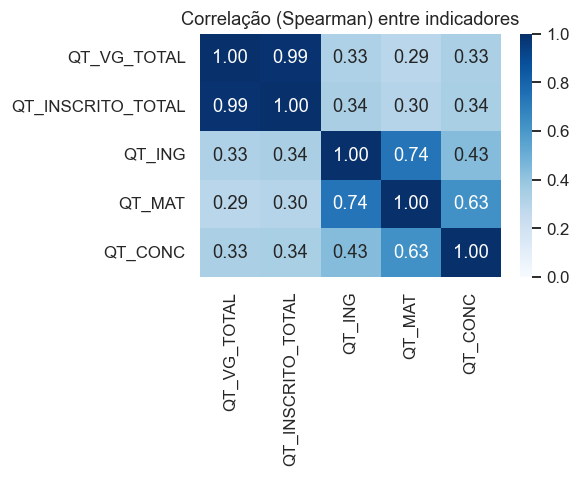

In [34]:
corr = base[num_cols].corr(method="spearman")

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Correlação (Spearman) entre indicadores")
plt.tight_layout()
plt.savefig("fig_correlacao.png", bbox_inches="tight")
plt.show()

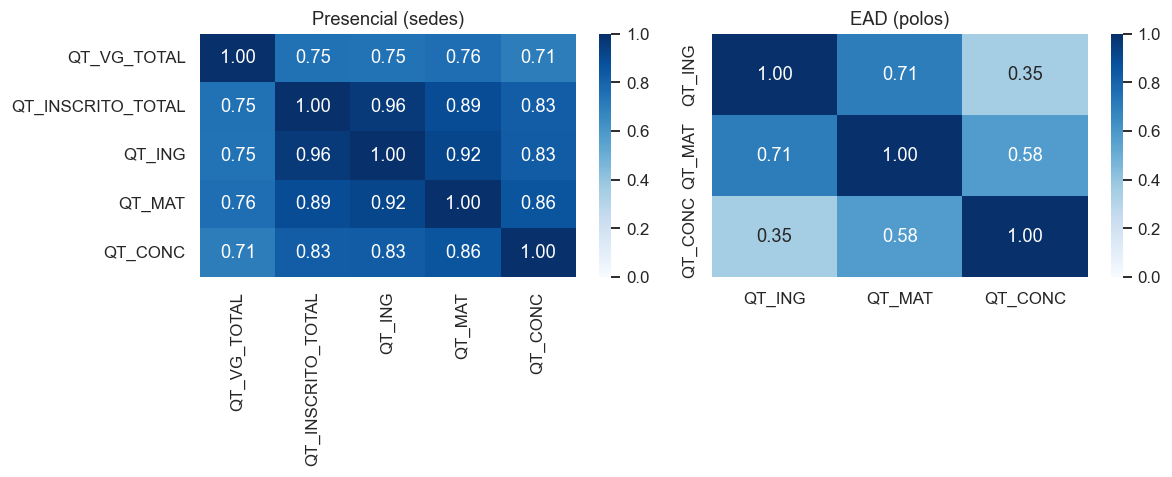

In [35]:
pres = base[base["TP_DIMENSAO"] == 1]
ead = base[base["TP_DIMENSAO"] == 2]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(pres[num_cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Presencial (sedes)")

sns.heatmap(ead[["QT_ING", "QT_MAT", "QT_CONC"]].corr(method="spearman"), annot=True,
            fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("EAD (polos)")

plt.tight_layout()
plt.savefig("fig_correlacao_por_modalidade.png", bbox_inches="tight")
plt.show()

Na base inteira, vagas e inscritos aparecem quase perfeitamente correlacionados (0,99), mas esse valor é em grande parte estrutural: as duas variáveis são zero em todos os polos EAD e só são informadas nas sedes presenciais. Por isso, a correlação foi recalculada separadamente por modalidade.

No presencial, vagas e inscritos têm correlação de 0,75; ingressantes e matrículas, 0,92; matrículas e concluintes, 0,86. No EAD (por polo), ingressantes e matrículas têm correlação de 0,71, mas ingressantes e concluintes apenas 0,35, uma ligação bem mais fraca entre entrar e concluir o curso.

Na base inteira, vagas e inscritos têm correlação fraca com ingressantes, matrículas e concluintes (0,29 a 0,34). Isso também reflete a diferença de registro entre as modalidades, e não necessariamente uma baixa conversão. Ingressantes e matrículas têm correlação forte entre si (0,74), como esperado.

## 9. Comparação Presencial x EAD

In [36]:
comparativo = base.groupby("MODALIDADE", observed=True)[num_cols].sum()
comparativo

,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC
MODALIDADE,,,,,
EAD,0,0,8596,9487,1721
Presencial,14972,20838,9054,13121,2257


In [37]:
razao = (comparativo["QT_MAT"] / comparativo["QT_ING"]).round(2).rename("matriculas_por_ingressante")
razao

MODALIDADE
EAD           1.10
Presencial    1.45
Name: matriculas_por_ingressante, dtype: float64

In [38]:
resumo_mod = base.groupby("MODALIDADE")["QT_MAT"].agg(
    registros="count",
    media="mean",
    mediana="median",
    pct_zero=lambda s: (s == 0).mean() * 100
).round(1)
resumo_mod

,registros,media,mediana,pct_zero
MODALIDADE,,,,
EAD,1565,6.1,1.0,27.3
Presencial,76,172.6,120.0,9.2


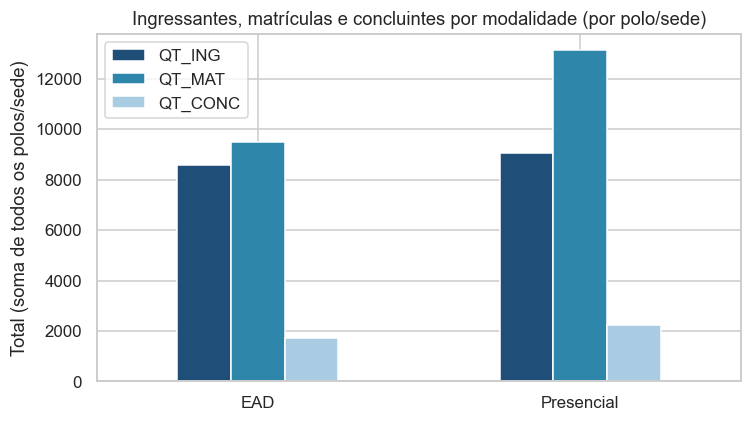

In [39]:
# QT_VG_TOTAL/QT_INSCRITO_TOTAL da EAD só existem no agregado nacional (fora de "base"),
# por isso ficam de fora deste gráfico: aqui comparamos só o que é registrado por polo/sede
# nas duas modalidades.
fig, ax = plt.subplots(figsize=(7, 4))
comparativo[["QT_ING", "QT_MAT", "QT_CONC"]].plot(kind="bar", ax=ax, color=["#1F4E79", "#2E86AB", "#A9CCE3"])
ax.set_title("Ingressantes, matrículas e concluintes por modalidade (por polo/sede)")
ax.set_ylabel("Total (soma de todos os polos/sede)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("fig_comparativo_modalidade.png", bbox_inches="tight")
plt.show()

Um achado estrutural importante aparece aqui: no nível de sede/polo, a EAD mostra zero em vagas ofertadas e inscritos. Isso não é um erro. O Censo só registra vagas e inscritos da EAD no agregado nacional (as 10 linhas separadas na seção 4), nunca por polo individual, enquanto o presencial informa vagas por campus normalmente. Ingressantes, matrículas e concluintes seguem registrados por polo nas duas modalidades, o que permite a comparação.

Considerando só o que é comparável, o presencial tem 1,45 matrícula para cada ingressante, contra 1,10 na EAD. Essa razão não deve ser lida como taxa de conversão: as matrículas somam alunos de todos os períodos do curso, então a razão reflete também a duração do curso e a permanência dos alunos. A leitura segura é que o presencial acumula mais alunos por ingressante. Essa diferença de granularidade entre as modalidades é uma limitação da base, a ser registrada na proposta analítica.

## 10. Perfil das demais variáveis (categóricas e constantes)

Até aqui o foco foram as 5 variáveis numéricas. Esta seção completa o perfil das outras 13
colunas selecionadas, para não deixar nenhuma variável fora da análise.

In [40]:
colunas_constantes = ["NU_ANO_CENSO", "CO_IES", "CO_CINE_AREA_GERAL", "NO_CINE_AREA_GERAL"]
for c in colunas_constantes:
    print(f"{c}: {df[c].nunique()} valor único -> {df[c].iloc[0]}")

NU_ANO_CENSO: 1 valor único -> 2024
CO_IES: 1 valor único -> 322
CO_CINE_AREA_GERAL: 1 valor único -> 6
NO_CINE_AREA_GERAL: 1 valor único -> Computação e Tecnologias da Informação e Comunicação (TIC)


Essas 4 colunas têm um único valor em toda a base — o que é esperado e confirma que o filtro
(UNIP + área de Computação/TIC) foi aplicado corretamente. Não há o que analisar em termos de
distribuição nelas.

In [41]:
print(df["NO_CINE_ROTULO"].value_counts())
print()
# checar se cada curso corresponde a um único rótulo CINE
print(df.groupby("NO_CURSO", observed=True)["NO_CINE_ROTULO"].nunique())

NO_CINE_ROTULO
Sistemas de informação                433
Gestão da tecnologia da informação    369
Ciência da computação                 317
Redes de computadores                 275
Segurança da informação               255
Jogos digitais                          2
Name: count, dtype: int64

NO_CURSO
Análise E Desenvolvimento De Sistemas    1
Ciência Da Computação                    1
Gestão Da Tecnologia Da Informação       1
Jogos Digitais                           1
Redes De Computadores                    1
Segurança Da Informação                  1
Sistemas De Informação                   1
Name: NO_CINE_ROTULO, dtype: int64


`NO_CINE_ROTULO` é a classificação padronizada CINE Brasil (uma taxonomia oficial), diferente do nome do curso dado pela própria UNIP (`NO_CURSO`). Cada curso da UNIP corresponde a exatamente um rótulo CINE, mas o contrário não vale: o curso "Análise e Desenvolvimento de Sistemas" (424 registros) e o curso "Sistemas de Informação" (9 registros) recebem o mesmo rótulo "Sistemas de informação" (433 registros no total). Por isso são 7 cursos e 6 rótulos, e as duas colunas não são totalmente redundantes: `NO_CURSO` é mais detalhada.

In [42]:
print(df["TP_GRAU_ACADEMICO"].value_counts())
print()
print(pd.crosstab(df["NO_CURSO"], df["TP_GRAU_ACADEMICO"]))

TP_GRAU_ACADEMICO
3    1325
1     326
Name: count, dtype: int64

TP_GRAU_ACADEMICO                        1    3
NO_CURSO                                       
Análise E Desenvolvimento De Sistemas    0  424
Ciência Da Computação                  317    0
Gestão Da Tecnologia Da Informação       0  369
Jogos Digitais                           0    2
Redes De Computadores                    0  275
Segurança Da Informação                  0  255
Sistemas De Informação                   9    0


`TP_GRAU_ACADEMICO` tem 2 valores: 1 (Bacharelado), com 326 registros — só em Ciência da
Computação e Sistemas de Informação —, e 3 (Tecnólogo), com 1.325 registros, nos demais 5
cursos. Faz sentido: são as duas únicas formações de bacharelado da lista, o resto é
tecnólogo (curso mais curto), o que é típico da oferta EAD em massa.

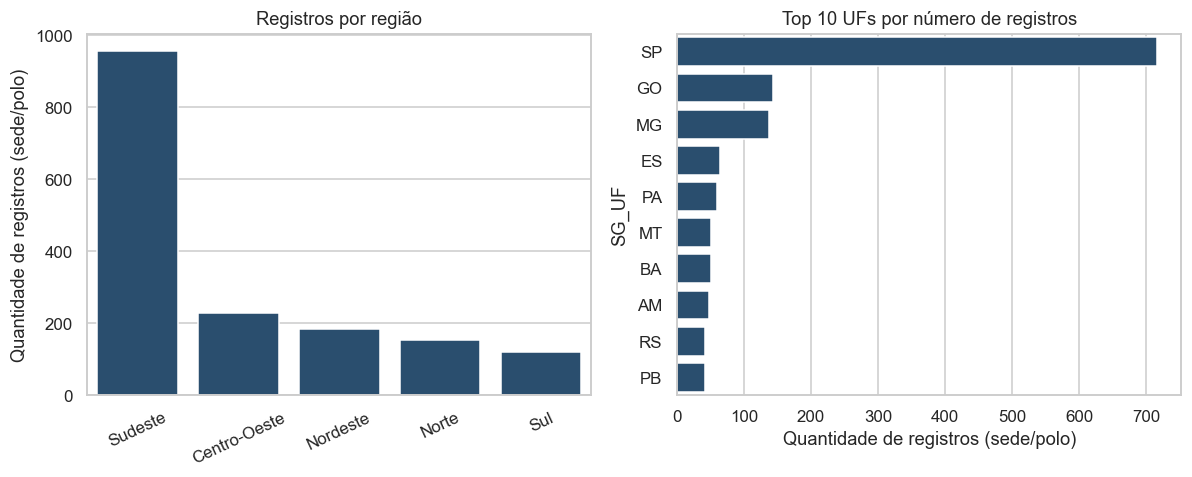

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.countplot(data=base, x="NO_REGIAO", order=base["NO_REGIAO"].value_counts().index, ax=axes[0], color="#1F4E79")
axes[0].set_title("Registros por região")
axes[0].set_xlabel("")
axes[0].set_ylabel("Quantidade de registros (sede/polo)")
axes[0].tick_params(axis='x', rotation=25)

top_uf = base["SG_UF"].value_counts().head(10)
sns.barplot(x=top_uf.values, y=top_uf.index, ax=axes[1], color="#1F4E79", order=top_uf.index)
axes[1].set_title("Top 10 UFs por número de registros")
axes[1].set_xlabel("Quantidade de registros (sede/polo)")

plt.tight_layout()
plt.savefig("fig_regiao_uf.png", bbox_inches="tight")
plt.show()

A região Sudeste concentra 956 dos 1.641 registros (58%), com São Paulo isoladamente
respondendo por 717 (44% da base) — coerente com a sede da UNIP ser paulista. As demais 26
UFs dividem o restante, numa cauda longa (a menor, AP, tem só 3 registros). `NO_MUNICIPIO` tem
490 valores distintos, granularidade demais para um gráfico único; os 3 municípios com mais
registros são exibidos abaixo.

In [44]:
base["NO_MUNICIPIO"].value_counts().head(3).to_frame("registros")

,registros
NO_MUNICIPIO,
São Paulo,37
Campinas,11
Santana de Parnaíba,10


**Conclusão desta seção:** todas as 18 colunas selecionadas foram perfiladas — 4 são
constantes (confirmam o filtro), 5 numéricas foram detalhadas nas seções 5 a 9, e as 9
restantes (curso, rótulo CINE, grau acadêmico, modalidade, dimensão, região, UF e município)
tiveram sua distribuição descrita nesta seção e na seção 7. Não sobra nenhuma variável sem
análise para a próxima etapa.

## 11. Outliers — resumo

Outliers calculados pelo método do intervalo interquartil (IQR): valores acima de
Q3 + 1,5×IQR.

In [45]:
# IQR só para variáveis em que Q1 e Q3 não são zero em bloco
cols_iqr = ["QT_ING", "QT_MAT", "QT_CONC"]
resumo_outliers = []
for c in cols_iqr:
    q1, q3 = base[c].quantile(0.25), base[c].quantile(0.75)
    iqr = q3 - q1
    limite = q3 + 1.5 * iqr
    n_out = (base[c] > limite).sum()
    resumo_outliers.append({
        "variavel": c, "Q1": q1, "Q3": q3, "limite_superior": limite,
        "outliers": n_out, "outliers_%": round(n_out / len(base) * 100, 1)
    })
display(pd.DataFrame(resumo_outliers))

# Vagas e inscritos: verificar de onde vêm os valores positivos
for c in ["QT_VG_TOTAL", "QT_INSCRITO_TOTAL"]:
    positivos = base[base[c] > 0]
    print(f"{c}: {len(positivos)} linhas com valor positivo; "
          f"todas presenciais? {(positivos['TP_DIMENSAO'] == 1).all()}")

,variavel,Q1,Q3,limite_superior,outliers,outliers_%
0,QT_ING,0.0,3.0,7.5,234,14.3
1,QT_MAT,0.0,4.0,10.0,200,12.2
2,QT_CONC,0.0,1.0,2.5,174,10.6


QT_VG_TOTAL: 76 linhas com valor positivo; todas presenciais? True
QT_INSCRITO_TOTAL: 74 linhas com valor positivo; todas presenciais? True


Outliers calculados pelo método do intervalo interquartil (IQR): valores acima de Q3 + 1,5×IQR. O método foi aplicado a ingressantes, matrículas e concluintes, onde 10,6% a 14,3% das linhas ficam acima do limite. Não são erros: são as sedes e os polos com maior volume de alunos frente à maioria de polos pequenos. Por isso não foram removidos, apenas identificados.

Para vagas e inscritos o IQR não se aplica: Q1, Q3 e o limite superior são todos zero, então qualquer valor positivo seria classificado como outlier. Esses valores positivos vêm somente das sedes presenciais, o único grupo que informa essas variáveis por unidade, e não de unidades atípicas.

Resumo do que foi feito: 1.651 registros e 18 colunas selecionadas, com 10 linhas agregadas separadas (estrutura própria do Censo) e 1.641 linhas por sede/polo usadas nas estatísticas. Não há valores ausentes nas variáveis numéricas. A distribuição é muito assimétrica, com outliers legítimos nas maiores sedes e polos, e as vagas e inscritos do EAD só existem no agregado nacional. Esses achados orientam a proposta analítica e as análises comparativas das próximas etapas.